# Lab Notebook 3 · PCA three ways
**Project:** WNBA 2025 shot chart (one row = one field-goal attempt)  
**Data:** `wnba_clean.csv` (frozen file; 38,535 rows)  
**Seed:** 651 (PCA is deterministic, so no random step is needed)

**This is an unsupervised PCA:** it uses only the input measurements. The outcome (`made_flag`) and the treatment flag (`is_dynamic_shot`, built from `action_type`) are never part of the matrix.

**Plan:** run PCA on the same standardized matrix `Z` using (1) eigendecomposition of the covariance matrix, (2) SVD of `Z`, and (3) `sklearn.decomposition.PCA`. Then check that all three agree, draw a scree plot, and say what two components throw away.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

SEED = 651
CLEAN = "../wnba_clean.csv"      
df = pd.read_csv(CLEAN)
print("shape:", df.shape)

shape: (38535, 22)


## 1. Choose the feature matrix
PCA is unsupervised, so it should only see the raw input measurements. I leave out the outcome (`made_flag`), the ID columns (`game_id`, `game_event_id`, `player_id`, `team_id`), which are labels and not measurements, and the `is_dynamic_shot` flag, which is my treatment variable built from the text in `action_type`. That leaves the numeric measurements from the clean file.

In [2]:
FEATURES = ["period", "seconds_left", "shot_distance", "loc_x", "loc_y",
            "is_overtime", "is_backcourt"]

# unsupervised guard: no outcome, no treatment flag, no IDs in the matrix
FORBIDDEN = {"made_flag", "is_dynamic_shot", "action_type",
             "game_id", "game_event_id", "player_id", "team_id"}
assert not FORBIDDEN & set(FEATURES)

X = df[FEATURES].to_numpy(dtype=float)
n, p = X.shape
print("X:", X.shape)

X: (38535, 7)


## 2. Standardize
The columns are on very different scales (`loc_y` runs to ~760, `is_overtime` is 0/1), so without scaling PCA would just follow the biggest numbers. I z-score every column with `ddof=1`, so the covariance matrix of `Z` is the correlation matrix of `X`. All three methods start from this same `Z`.

In [3]:
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
print("column means (should be ~0):", Z.mean(axis=0).round(10))
print("column stds  (should be 1): ", Z.std(axis=0, ddof=1).round(10))

column means (should be ~0): [ 0. -0.  0.  0.  0. -0. -0.]
column stds  (should be 1):  [1. 1. 1. 1. 1. 1. 1.]


## 3. Method 1 · Eigendecomposition of the covariance matrix
`C = Zᵀ Z / (n-1)` is symmetric, so `np.linalg.eigh` gives real eigenvalues and orthonormal eigenvectors. `eigh` returns them in ascending order, so I sort them descending.

In [4]:
C = np.cov(Z, rowvar=False)                 # p x p covariance (= correlation matrix of X)
eigvals, eigvecs = np.linalg.eigh(C)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

lam_eig = eigvals                            # variance along each PC
V_eig = eigvecs                              # columns = principal axes (loadings)
scores_eig = Z @ V_eig                       # n x p PC scores
print("eigenvalues:", lam_eig.round(4))

eigenvalues: [1.9157 1.1304 1.0201 0.9936 0.8739 0.8691 0.1971]


## 4. Method 2 · SVD of the data matrix
`Z = U S Vᵀ`. The columns of `V` are the same principal axes, and the eigenvalues of `C` are `S² / (n-1)`. The scores are `U S`.

In [5]:
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
lam_svd = S**2 / (n - 1)
V_svd = Vt.T
scores_svd = U * S
print("eigenvalues from S^2/(n-1):", lam_svd.round(4))

eigenvalues from S^2/(n-1): [1.9157 1.1304 1.0201 0.9936 0.8739 0.8691 0.1971]


## 5. Method 3 · scikit-learn
`PCA` centers the data itself and uses SVD under the hood. I pass it the already-standardized `Z` so it is solving the same problem.

In [6]:
sk = PCA(n_components=p).fit(Z)
lam_sk = sk.explained_variance_
V_sk = sk.components_.T                      # sklearn stores axes as rows
scores_sk = sk.transform(Z)
print("sklearn explained_variance_:", lam_sk.round(4))

sklearn explained_variance_: [1.9157 1.1304 1.0201 0.9936 0.8739 0.8691 0.1971]


## 6. Do all three agree?
Eigenvalues are unique, but each eigenvector (and so each score column) is only defined **up to a sign**: `v` and `-v` are equally valid. So before comparing loadings and scores I flip each column of the SVD and sklearn results to match the sign of the eigendecomposition result.

In [7]:
def match_signs(ref, other):
    s = np.sign(np.sum(ref * other, axis=0))
    s[s == 0] = 1
    return other * s

V_svd_a, V_sk_a = match_signs(V_eig, V_svd), match_signs(V_eig, V_sk)
sc_svd_a, sc_sk_a = match_signs(scores_eig, scores_svd), match_signs(scores_eig, scores_sk)

report = pd.DataFrame({
    "eig vs SVD": [np.abs(lam_eig - lam_svd).max(), np.abs(V_eig - V_svd_a).max(), np.abs(scores_eig - sc_svd_a).max()],
    "eig vs sklearn": [np.abs(lam_eig - lam_sk).max(), np.abs(V_eig - V_sk_a).max(), np.abs(scores_eig - sc_sk_a).max()],
}, index=["eigenvalues", "loadings", "scores"])
print("largest absolute difference:")
print(report.to_string(float_format=lambda v: f"{v:.2e}"))

assert np.allclose(lam_eig, lam_svd) and np.allclose(lam_eig, lam_sk)
assert np.allclose(V_eig, V_svd_a) and np.allclose(V_eig, V_sk_a)
assert np.allclose(scores_eig, sc_svd_a, atol=1e-8) and np.allclose(scores_eig, sc_sk_a, atol=1e-8)
print("\nAll three methods agree (eigenvalues, loadings, scores).")
print("sum of eigenvalues =", lam_eig.sum().round(6), "| number of features =", p, "(standardized data: they match)")

largest absolute difference:
             eig vs SVD  eig vs sklearn
eigenvalues    6.22e-15        8.88e-16
loadings       4.93e-13        1.03e-14
scores         9.65e-12        2.03e-13

All three methods agree (eigenvalues, loadings, scores).
sum of eigenvalues = 7.0 | number of features = 7 (standardized data: they match)


## 7. Variance explained and scree plot

In [8]:
evr = lam_eig / lam_eig.sum()
cum = np.cumsum(evr)
table = pd.DataFrame({"eigenvalue": lam_eig, "variance ratio": evr, "cumulative": cum},
                     index=[f"PC{i+1}" for i in range(p)])
print(table.round(4).to_string())

     eigenvalue  variance ratio  cumulative
PC1      1.9157          0.2737      0.2737
PC2      1.1304          0.1615      0.4352
PC3      1.0201          0.1457      0.5809
PC4      0.9936          0.1419      0.7228
PC5      0.8739          0.1248      0.8477
PC6      0.8691          0.1242      0.9718
PC7      0.1971          0.0282      1.0000


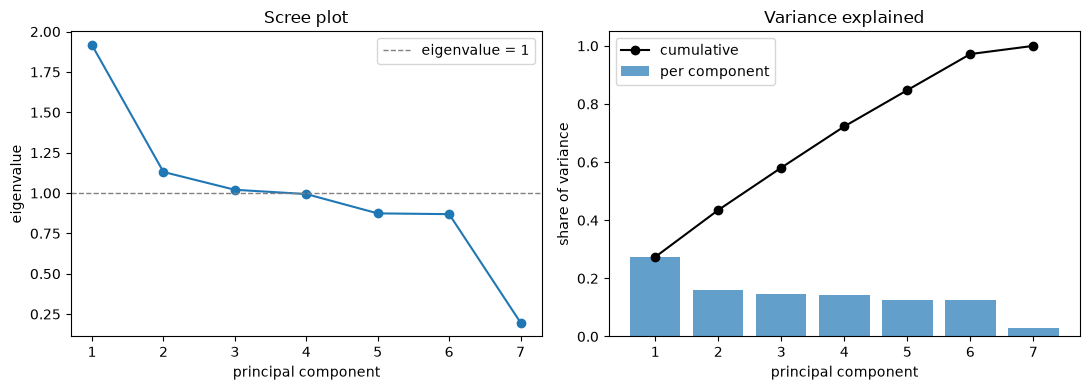

In [9]:
pcs = np.arange(1, p + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(pcs, lam_eig, "o-")
ax[0].axhline(1, ls="--", color="gray", lw=1, label="eigenvalue = 1")
ax[0].set_xlabel("principal component"); ax[0].set_ylabel("eigenvalue")
ax[0].set_title("Scree plot"); ax[0].legend()

ax[1].bar(pcs, evr, alpha=0.7, label="per component")
ax[1].plot(pcs, cum, "o-", color="k", label="cumulative")
ax[1].set_xlabel("principal component"); ax[1].set_ylabel("share of variance")
ax[1].set_title("Variance explained"); ax[1].legend()

for a in ax: a.set_xticks(pcs)
plt.tight_layout()
plt.savefig("pca_scree_plot.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. What do the first components mean?

In [10]:
loadings = pd.DataFrame(V_eig[:, :3], index=FEATURES, columns=["PC1", "PC2", "PC3"])
print(loadings.round(3).to_string())

                 PC1    PC2    PC3
period        -0.013 -0.654 -0.315
seconds_left  -0.097  0.276 -0.682
shot_distance  0.661  0.015 -0.154
loc_x         -0.015 -0.054  0.540
loc_y          0.669  0.012 -0.103
is_overtime   -0.007 -0.702 -0.029
is_backcourt   0.327 -0.016  0.331


## 9. What two components lose
To see exactly what is lost, I rebuild `Z` from only PC1 and PC2 and ask how much of each feature survives (R² of the rebuilt column against the original).

In [11]:
Z2 = scores_eig[:, :2] @ V_eig[:, :2].T
kept = 1 - ((Z - Z2) ** 2).mean(axis=0)          # per-feature share of variance kept
print(f"variance kept by 2 components: {cum[1]:.1%}  |  thrown away: {1 - cum[1]:.1%}")
print("check: mean squared rebuild error =", round(((Z - Z2) ** 2).mean(), 4),
      "= sum of dropped eigenvalues / p =", round(lam_eig[2:].sum() / p, 4))
print()
print(pd.Series(kept, index=FEATURES, name="share of each feature kept").round(3).to_string())

variance kept by 2 components: 43.5%  |  thrown away: 56.5%
check: mean squared rebuild error = 0.5648 = sum of dropped eigenvalues / p = 0.5648

period           0.483
seconds_left     0.104
shot_distance    0.836
loc_x            0.004
loc_y            0.856
is_overtime      0.558
is_backcourt     0.205


**Two sentences on what two components lose.**
Keeping only PC1 and PC2 retains just 43.5% of the total variance, so about 56% of the information in the data is discarded, and the scree plot levels off right after PC1 (PC2 through PC6 all have eigenvalues between 0.87 and 1.13), which means the variation is spread across many directions rather than concentrated in two. The 2D picture mostly keeps distance from the basket (PC1: `shot_distance` and `loc_y`) and game period (PC2: `period` and `is_overtime`), while it almost completely loses `loc_x` (0.4% kept) and keeps little of `seconds_left` (10%) and `is_backcourt` (21%), so the game-clock and court-width detail that my late-game question depends on is mostly gone.

## 10. Post-hoc check (not used in fitting)
The fit above never saw `made_flag`. As a sanity check afterwards, I can see how each component relates to the outcome. This only describes the result; it does not feed back into PCA.

In [12]:
corr_with_outcome = [np.corrcoef(scores_eig[:, k], df["made_flag"])[0, 1] for k in range(p)]
print(pd.Series(corr_with_outcome, index=[f"PC{i+1}" for i in range(p)], name="corr with made_flag").round(3).to_string())

PC1   -0.196
PC2    0.009
PC3    0.033
PC4   -0.012
PC5   -0.019
PC6    0.037
PC7    0.056


## AI Note
- **What AI helped with:** an AI assistant (Claude) drafted this notebook's structure and code.
- **What I checked and can explain:** Why I standardize first, why eigenvectors only match up to sign, why eigenvalues equal S² / (n-1))
- **Decisions that are mine:** I chose the 7 features, and excluded`made_flag` and `is_dynamic_shot` to keep PCA unsupervised)